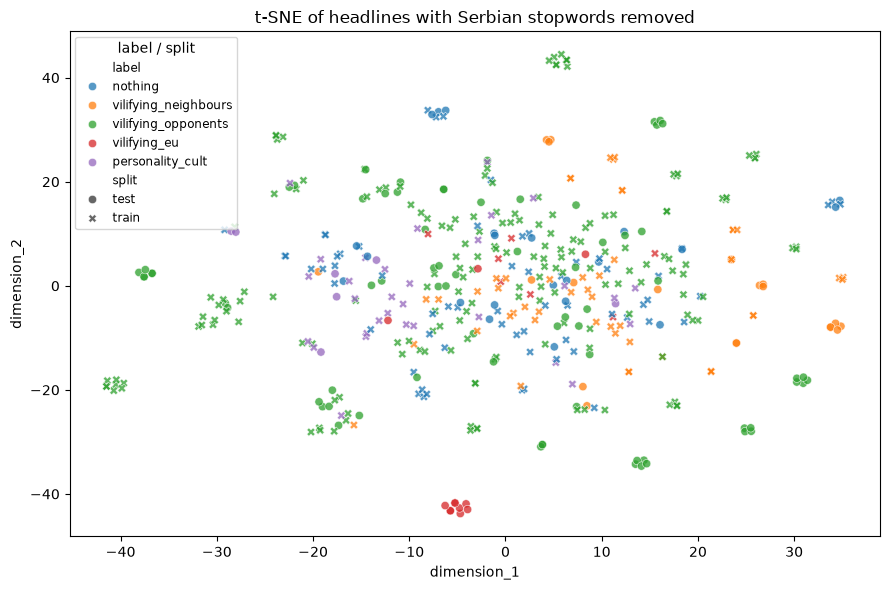

Train rows: 323; test rows: 132
Train accuracy: 1.000
Test accuracy: 0.720
Test balanced accuracy: 0.531
Majority baseline test accuracy: 0.538


In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.pipeline import make_pipeline

sys.path.insert(0, str(Path.cwd()))

from data import load_data, load_stopwords, make_groups
from evaluation import split_data

data = load_data("../data/processed/headlines.csv")
data["group"] = make_groups(data)
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]
data["split"] = "train"
data.loc[data.index[test_indices], "split"] = "test"

stopwords = load_stopwords()
perplexity = min(20, max(5, (len(data) - 1) // 3))
vectorizer = TfidfVectorizer(
    stop_words=stopwords,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=1,
)
features = vectorizer.fit_transform(data["headline"])
n_components = min(50, features.shape[1] - 1, features.shape[0] - 1)
reduced = TruncatedSVD(n_components=n_components, random_state=42).fit_transform(features)
embedding = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="random",
    random_state=42,
).fit_transform(reduced)

plot_data = pd.DataFrame(embedding, columns=["dimension_1", "dimension_2"])
plot_data["label"] = data["label"].to_numpy()
plot_data["split"] = data["split"].to_numpy()
fig, axis = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=plot_data,
    x="dimension_1",
    y="dimension_2",
    hue="label",
    style="split",
    ax=axis,
    alpha=0.75,
)
axis.set_title("t-SNE of headlines with Serbian stopwords removed")
axis.legend(title="label / split", fontsize="small")
plt.tight_layout()
plt.show()

classifier = make_pipeline(
    TfidfVectorizer(
        stop_words=stopwords,
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=1,
    ),
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
)
classifier.fit(train["headline"], train["label"])
train_predictions = classifier.predict(train["headline"])
test_predictions = classifier.predict(test["headline"])
majority_label = train["label"].value_counts().idxmax()
baseline_predictions = [majority_label] * len(test)

print(f"Train rows: {len(train)}; test rows: {len(test)}")
print(f"Train accuracy: {accuracy_score(train['label'], train_predictions):.3f}")
print(f"Test accuracy: {accuracy_score(test['label'], test_predictions):.3f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(test['label'], test_predictions):.3f}")
print(f"Majority baseline test accuracy: {accuracy_score(test['label'], baseline_predictions):.3f}")

# t-SNE visualization and evaluation

Serbian stopwords are removed during TF-IDF vectorization. The vectors are reduced with TruncatedSVD before t-SNE because the original matrix is sparse and high-dimensional. The plot includes all headlines for exploration; its train/test markers do not make it a held-out evaluation.

The printed accuracy scores come from a separate TF-IDF + logistic-regression classifier fit only on the training split, with duplicate clusters kept together by `GroupShuffleSplit`. They are not t-SNE accuracy: t-SNE is a visualization algorithm and does not provide a transform for unseen headlines.